# Text, graph, time-series classification

Figure 3b-d use AG News, Cora and UCI-HAR, respectively. Run this notebook from
top to bottom to preprocess the original datasets, generate synthetic supports,
evaluate unseen reservoir-type ONNs and display the results.



## Run configuration
The default uses the validation-selected publication ridge parameters. Set
`SEARCH_LAMBDA=True` to repeat their validation search before training.


In [1]:
import torch

SAVE_DETAILS = False  # Optional per-run diagnostics; keep inputs needed by SI.

REBUILD_PREPROCESSING = True
SEARCH_LAMBDA = False
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'  # Choose an available CUDA device, or 'cpu'.


In [2]:
from pathlib import Path
from utils.datasets import flat_result_path, flat_result_directory
import json
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from utils.datasets import load_npz, save_npz, random_coreset
from utils.reservoir_onn import tm_ensemble, set_seed
from utils.distillation import DistillationConfig, distill_coreset
from utils.evaluation import evaluate_coreset
from utils.preprocessing import preprocess_agnews, preprocess_cora, preprocess_uci_har, preprocessing_table
from utils.classification import (
    distill_classification, distill_timeseries, evaluate_support, evaluate_full,
    search_random_lambda, search_full_lambda, search_text_lambda, search_text_full_lambda,
)
from utils.plotting import (
    publication_style, classification_table, plot_classification_sweep, plot_classification_confusions,
)

get_ipython().run_line_magic('matplotlib', 'inline')
publication_style()
torch.set_num_threads(4)
CPU_THREADS = threadpool_limits(limits=4)
ROOT = Path.cwd()
DATA = ROOT / 'dataset'
PROCESSED = ROOT / 'results/cache/datasets'
OUTPUT = ROOT / 'results/simulation/multimodal'
EXPERIMENTAL = ROOT / 'results/experimental'
for folder in [PROCESSED, OUTPUT]:
    flat_result_directory(folder).mkdir(parents=True, exist_ok=True)
selection = {'agnews': {'coreset': {'5': 1.0, '10': 1.0, '20': 1.0, '30': 1.0, '60': 1.0, '120': 1.0},
            'random': {'5': 1.0, '10': 1.0, '20': 1.0, '30': 1.0, '60': 1.0, '120': 1.0},
            'full': 0.0001},
 'cora': {'per_repetition': [[10.0, 1.0, 1.0, 1.0, 1.0],
                             [10.0, 1.0, 1.0, 1.0, 1.0],
                             [10.0, 1.0, 1.0, 1.0, 1.0],
                             [10.0, 1.0, 1.0, 1.0, 1.0],
                             [10.0, 1.0, 1.0, 1.0, 1.0]],
          'full_per_repetition': [0.1, 0.1, 0.1, 0.1, 0.1]},
 'uci_har': {'coreset': [0.0001, 0.001, 0.01, 0.01, 0.1, 0.1],
             'random': [10.0, 10.0, 1.0, 1.0, 1.0, 1.0],
             'full': 1.0}}
REPETITIONS, TRAINING_TMS, VALIDATION_TMS, TEST_TMS, OUTPUT_DIM = 5, 50, 10, 50, 1024


## Figure 3b: news topic classification

### Preprocess AG News



In [3]:
TEXT_SIZES = [5, 10, 20, 30, 60, 120]
TEXT_SEED = 2026
text_data = preprocess_agnews(DATA / 'AGNews', device=DEVICE,
    cache_path=PROCESSED / 'agnews.npz', seed=TEXT_SEED, rebuild=REBUILD_PREPROCESSING)
display(preprocessing_table(text_data))


,Split,Samples,Input dimensions,Samples per class
0,train,115979,100,"[28999, 29000, 28997, 28983]"
1,val,4000,100,"[1000, 1000, 1000, 1000]"
2,test,7599,100,"[1900, 1900, 1900, 1899]"


### Set or select ridge parameters


In [4]:
text_lambda = {int(k): float(v) for k, v in selection['agnews']['coreset'].items()}
text_random_lambda = {int(k): float(v) for k, v in selection['agnews']['random'].items()}
text_full_lambda = float(selection['agnews']['full'])
if SEARCH_LAMBDA:
    grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]
    searched = search_text_lambda(text_data, TEXT_SIZES, grid, output_dim=OUTPUT_DIM,
        tm_count=VALIDATION_TMS, random_draws=5, base_seed=TEXT_SEED, device=DEVICE)
    full_search = search_text_full_lambda(text_data, grid, output_dim=OUTPUT_DIM,
        tm_count=VALIDATION_TMS, base_seed=TEXT_SEED, device=DEVICE)
    text_lambda = searched['lambda_by_size']
    text_random_lambda = text_lambda.copy()
    text_full_lambda = float(full_search['selected_lambda'])
    save_npz(OUTPUT / 'agnews_lambda_search.npz', {k:v for k,v in searched.items() if k != 'lambda_by_size'})
print('Coreset and random lambda:', text_lambda, '| Full-data lambda:', text_full_lambda)


Coreset and random lambda: {5: 1.0, 10: 1.0, 20: 1.0, 30: 1.0, 60: 1.0, 120: 1.0} | Full-data lambda: 0.0001


### Distill and evaluate



In [5]:
coreset_scores = np.empty((REPETITIONS, len(TEXT_SIZES), TEST_TMS))
random_scores = np.empty_like(coreset_scores)
for rep in range(REPETITIONS):
    set_seed(TEXT_SEED + rep)
    train_seeds = np.arange(1000 + 1000*rep, 1000 + 1000*rep + TRAINING_TMS)
    test_seeds = np.arange(9000 + 1000*rep, 9000 + 1000*rep + TEST_TMS)
    train_tms = tm_ensemble(100, OUTPUT_DIM, train_seeds, DEVICE)
    test_tms = tm_ensemble(100, OUTPUT_DIM, test_seeds, DEVICE)
    for col, size in enumerate(TEXT_SIZES):
        config = DistillationConfig(num_classes=4, images_per_class=size,
            ridge_lambda=text_lambda[size], steps=600, target_batch_size=192, tms_per_step=3,
            lr_x=0.02, lr_y=0.005, temperature=0.25, temperature_lr=0.002,
            grad_clip=10.0, coreset_seed=TEXT_SEED+rep, batch_seed=TEXT_SEED+7000+rep,
            mask_parameterization='sigmoid', label_parameterization='softmax', tm_sampling='random')
        distilled = distill_coreset(text_data['x_train'], text_data['y_train'], train_tms, config)
        evaluated = evaluate_coreset(distilled.x_coreset, distilled.y_coreset,
            text_data['x_test'], text_data['y_test'], test_tms, text_lambda[size])
        rx, ry, hard, indices = random_coreset(text_data['x_train'], text_data['y_train'],
            size, TEXT_SEED+20000+rep, 4)
        random_evaluation = evaluate_coreset(rx, ry, text_data['x_test'], text_data['y_test'],
            test_tms, text_random_lambda[size])
        coreset_scores[rep, col] = evaluated['accuracy_per_tm']
        random_scores[rep, col] = random_evaluation['accuracy_per_tm']
        if size == 5 or SAVE_DETAILS:
            save_npz(OUTPUT / 'agnews' / f'spc{size}_rep{rep}.npz', {
                'synthetic_inputs': distilled.x_coreset, 'synthetic_labels': distilled.y_coreset,
                'hard_labels': distilled.coreset_labels, 'source_indices': distilled.coreset_indices,
                'loss': distilled.loss_history, 'temperature': distilled.final_temperature,
                'accuracy_per_tm': evaluated['accuracy_per_tm'], 'random_inputs': rx,
                'random_labels': hard, 'random_indices': indices,
                'random_accuracy_per_tm': random_evaluation['accuracy_per_tm'],
                'training_tm_seeds': train_seeds, 'test_tm_seeds': test_seeds}, config)
full_seeds = np.arange(TEXT_SEED+80000, TEXT_SEED+80000+TEST_TMS)
full_tms = tm_ensemble(100, OUTPUT_DIM, full_seeds, DEVICE)
full_evaluation = evaluate_coreset(text_data['x_train'], F.one_hot(text_data['y_train'], 4).float(),
    text_data['x_test'], text_data['y_test'], full_tms, text_full_lambda)
text_simulation = {'ipc_values': np.asarray(TEXT_SIZES), 'coreset_accuracy_per_tm': coreset_scores,
    'random_accuracy_per_tm': random_scores, 'coreset_accuracy': coreset_scores.mean(axis=2),
    'random_accuracy': random_scores.mean(axis=2), 'full_accuracy_per_tm': full_evaluation['accuracy_per_tm'],
    'full_mean': np.asarray(full_evaluation['accuracy_mean']), 'full_tm_seeds': full_seeds}
save_npz(OUTPUT / 'agnews_sweep.npz', text_simulation)
print('AG News complete')


AG News complete


### Coreset sweep and measured confusion matrices



,Samples per class,Coreset simulation (%),Coreset experiment (%),Random simulation (%),Random experiment (%)
0,5,78.23 ± 0.13,76.86 ± 1.24,39.62 ± 1.24,39.96 ± 1.37
1,10,79.32 ± 0.20,78.34 ± 0.76,47.04 ± 0.91,46.64 ± 1.94
2,20,80.83 ± 0.22,80.23 ± 0.76,55.33 ± 2.48,54.61 ± 2.91
3,30,81.74 ± 0.18,81.04 ± 0.60,61.37 ± 2.34,60.81 ± 2.65
4,60,82.84 ± 0.13,82.42 ± 0.37,71.81 ± 0.73,71.35 ± 0.79
5,120,83.51 ± 0.17,83.33 ± 0.34,78.10 ± 1.08,77.77 ± 1.06


Full training data: 85.53%


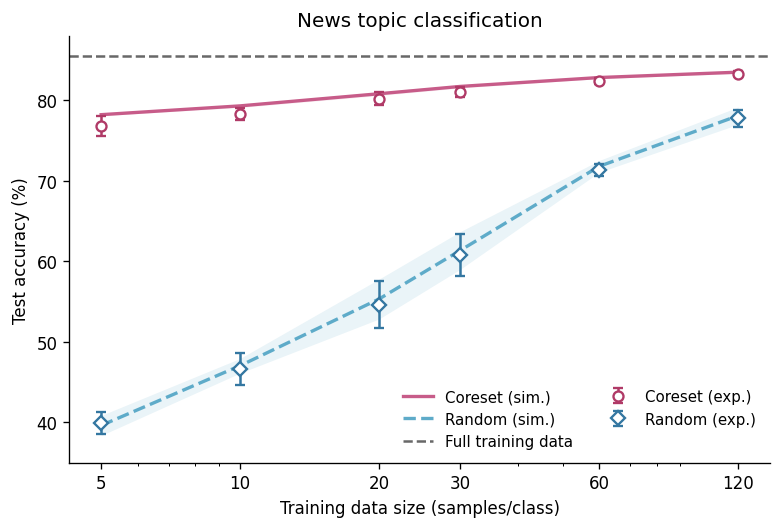

In [6]:
text_experiment = load_npz(EXPERIMENTAL / 'agnews_experiment.npz')
display(classification_table(text_simulation, text_experiment))
print(f"Full training data: {100*float(text_simulation['full_mean']):.2f}%")
fig = plot_classification_sweep(text_simulation, text_experiment, 'News topic classification', (35, 88))
plt.show()


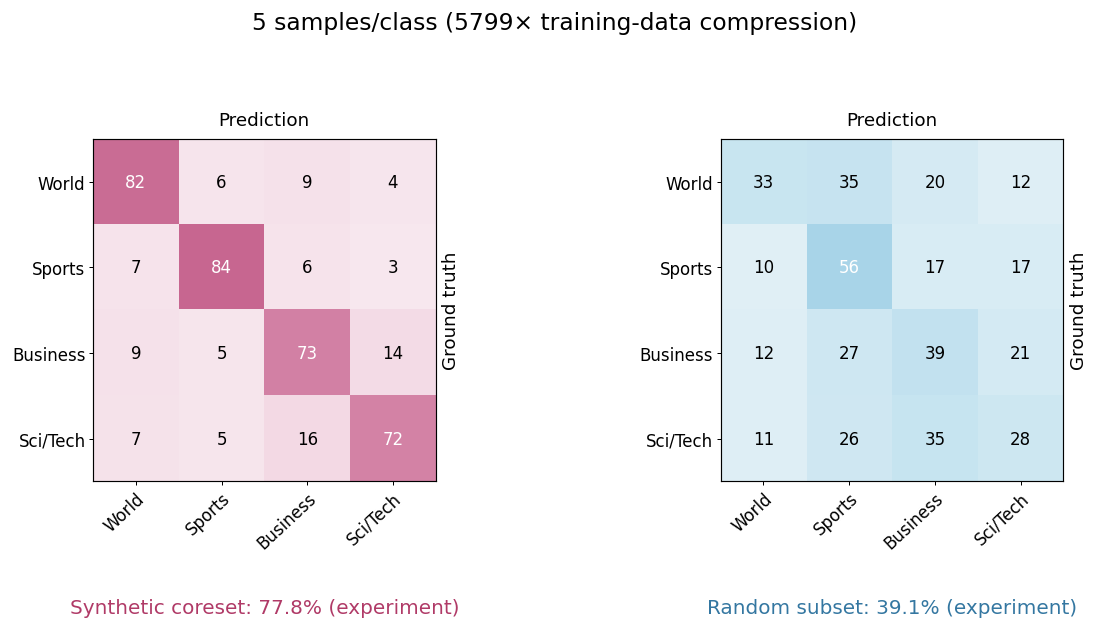

In [7]:
fig = plot_classification_confusions(text_experiment, ['World', 'Sports', 'Business', 'Sci/Tech'],
    len(text_data['x_train']))
plt.show()


## Figure 3c: citation-network node classification

### Preprocess Cora



In [8]:
GRAPH_SIZES = [1, 2, 5, 10, 20]
GRAPH_SEED = 20260812
graph_data = preprocess_cora(DATA / 'Cora', device=DEVICE,
    cache_path=PROCESSED / 'cora.npz', rebuild=REBUILD_PREPROCESSING)
display(preprocessing_table(graph_data))


,Split,Samples,Input dimensions,Samples per class
0,train,1624,100,"[211, 131, 250, 490, 256, 178, 108]"
1,val,542,100,"[70, 43, 84, 164, 85, 60, 36]"
2,test,542,100,"[70, 43, 84, 164, 85, 60, 36]"


### Distill, select validation checkpoints and evaluate



In [9]:
coreset_scores = np.empty((REPETITIONS, len(GRAPH_SIZES), TEST_TMS))
random_draw_scores = np.empty((REPETITIONS, len(GRAPH_SIZES), 20, TEST_TMS))
full_scores = np.empty((REPETITIONS, TEST_TMS))
for rep in range(REPETITIONS):
    seed = GRAPH_SEED + 100000*rep
    set_seed(seed)
    train_seeds = np.arange(seed+30000, seed+30000+TRAINING_TMS)
    validation_seeds = np.arange(seed+40000, seed+40000+VALIDATION_TMS)
    test_seeds = np.arange(seed+50000, seed+50000+TEST_TMS)
    train_tms = tm_ensemble(100, OUTPUT_DIM, train_seeds, DEVICE)
    validation_tms = tm_ensemble(100, OUTPUT_DIM, validation_seeds, DEVICE)
    test_tms = tm_ensemble(100, OUTPUT_DIM, test_seeds, DEVICE)
    selected = np.asarray(selection['cora']['per_repetition'][rep])
    full_lambda = float(selection['cora']['full_per_repetition'][rep])
    if SEARCH_LAMBDA:
        grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]
        searched = search_random_lambda(graph_data, GRAPH_SIZES, grid, validation_tms,
            random_draws=10, seed=seed+60000)
        selected = searched['selected_lambda']
        full_search = search_full_lambda(graph_data, grid, validation_tms)
        full_lambda = float(full_search['selected_lambda'])
        save_npz(OUTPUT / 'cora' / f'lambda_rep{rep}.npz', {k:v for k,v in searched.items() if k != 'lambda_by_size'})
    full_scores[rep] = evaluate_full(graph_data, test_tms, full_lambda, split='test')['accuracy_per_tm']
    for col, size in enumerate(GRAPH_SIZES):
        ridge_lambda = float(selected[col])
        distilled = distill_classification(graph_data, samples_per_class=size,
            ridge_lambda=ridge_lambda, train_tms=train_tms, validation_tms=validation_tms,
            steps=1000, batch_size=350, tms_per_step=5, lr_x=0.02, lr_y=0.005,
            temperature_init=0.25, temperature_lr=0.002, gradient_clip=10.0,
            seed=seed+70000+size, eval_every=25)
        evaluated = evaluate_support(distilled.x_coreset, distilled.y_coreset,
            graph_data['x_test'], graph_data['y_test'], test_tms, ridge_lambda)
        coreset_scores[rep,col] = evaluated['accuracy_per_tm']
        for draw in range(20):
            rx, ry, hard, indices = random_coreset(graph_data['x_train'], graph_data['y_train'],
                size, seed+80000+100*size+draw, 7)
            random_draw_scores[rep,col,draw] = evaluate_support(rx, ry,
                graph_data['x_test'], graph_data['y_test'], test_tms, ridge_lambda)['accuracy_per_tm']
        if size == 2 or SAVE_DETAILS:
            save_npz(OUTPUT / 'cora' / f'spc{size}_rep{rep}.npz', {
                **vars(distilled), 'accuracy_per_tm': coreset_scores[rep,col],
                'random_accuracy_per_draw_tm': random_draw_scores[rep,col],
                'training_tm_seeds': train_seeds, 'validation_tm_seeds': validation_seeds,
                'test_tm_seeds': test_seeds, 'ridge_lambda': ridge_lambda})
graph_simulation = {'ipc_values': np.asarray(GRAPH_SIZES), 'coreset_accuracy_per_tm': coreset_scores,
    'random_accuracy_per_draw_tm': random_draw_scores, 'coreset_accuracy': coreset_scores.mean(axis=2),
    'random_accuracy': random_draw_scores.mean(axis=2).mean(axis=2), 'full_accuracy_per_tm': full_scores,
    'full_mean': np.asarray(full_scores.mean())}
save_npz(OUTPUT / 'cora_sweep.npz', graph_simulation)
print('Cora complete')


Cora complete


### Coreset sweep and measured confusion matrices



,Samples per class,Coreset simulation (%),Coreset experiment (%),Random simulation (%),Random experiment (%)
0,1,79.91 ± 0.47,78.14 ± 1.29,32.09 ± 1.44,34.54 ± 3.78
1,2,85.35 ± 0.33,83.30 ± 1.74,43.97 ± 1.55,44.56 ± 3.48
2,5,86.20 ± 0.34,84.48 ± 0.98,59.67 ± 0.90,57.90 ± 4.08
3,10,86.98 ± 0.21,85.68 ± 1.04,68.94 ± 0.21,69.98 ± 2.46
4,20,87.11 ± 0.21,86.55 ± 0.77,75.98 ± 0.38,75.30 ± 2.36


Full training data: 88.47%


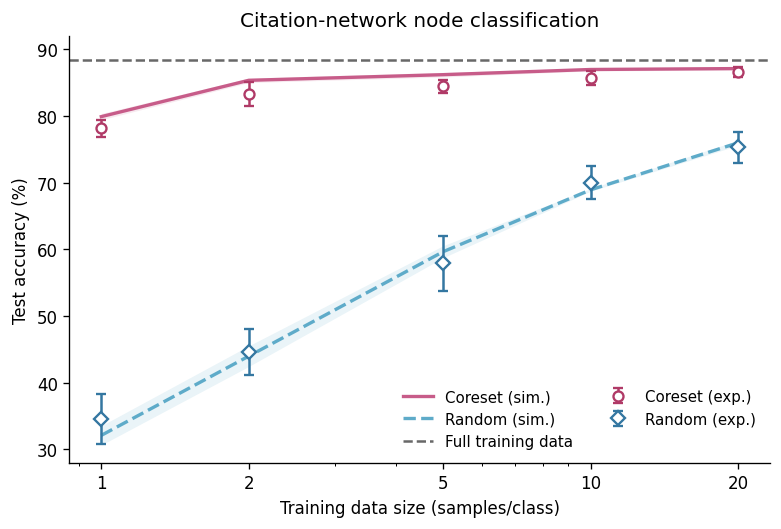

In [10]:
graph_experiment = load_npz(EXPERIMENTAL / 'cora_experiment.npz')
display(classification_table(graph_simulation, graph_experiment))
print(f"Full training data: {100*float(graph_simulation['full_mean']):.2f}%")
fig = plot_classification_sweep(graph_simulation, graph_experiment,
    'Citation-network node classification', (28, 92))
plt.show()


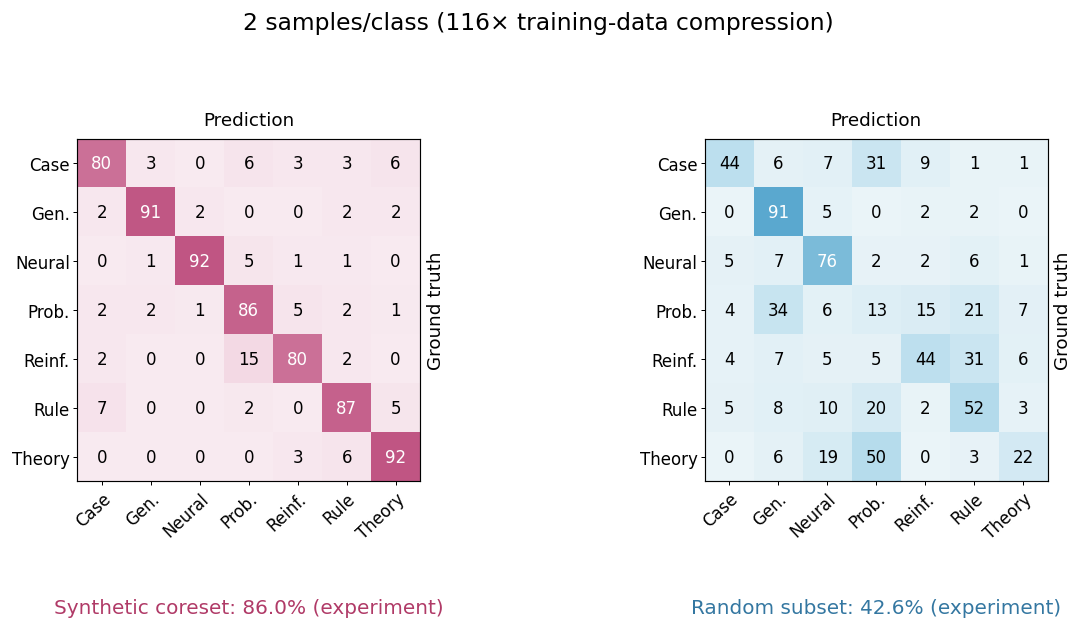

In [11]:
fig = plot_classification_confusions(graph_experiment,
    ['Case', 'Gen.', 'Neural', 'Prob.', 'Reinf.', 'Rule', 'Theory'], len(graph_data['x_train']))
plt.show()


## Figure 3d: human activity recognition

### Preprocess UCI-HAR



In [12]:
TIME_SIZES = [1, 2, 5, 10, 20, 50]
TIME_SEED = 20260815
time_data = preprocess_uci_har(DATA / 'UCI_HAR', device=DEVICE)
display(preprocessing_table(time_data))
print('Training subjects:', time_data['train_subjects'].tolist())
print('Validation subjects:', time_data['validation_subjects'].tolist())
print('Test subjects:', time_data['test_subjects'].tolist())
assert not set(time_data['train_subjects']) & set(time_data['validation_subjects'])
assert not (set(time_data['train_subjects']) | set(time_data['validation_subjects'])) & set(time_data['test_subjects'])
save_npz(PROCESSED / 'uci_har.npz', time_data)


,Split,Samples,Input dimensions,Samples per class
0,train,5888,1024,"[982, 863, 790, 1026, 1099, 1128]"
1,val,1464,1024,"[244, 210, 196, 260, 275, 279]"
2,test,2947,1024,"[496, 471, 420, 491, 532, 537]"


Training subjects: [1, 3, 5, 6, 7, 8, 11, 15, 16, 17, 21, 22, 26, 27, 28, 29, 30]
Validation subjects: [14, 19, 23, 25]
Test subjects: [2, 4, 9, 10, 12, 13, 18, 20, 24]


PosixPath('/home/laserthu/user_data/JJJ/release_validation/full_reproduction_20261022_002107/stage/results/cache__datasets__uci_har.npz')

### Set or select ridge parameters



In [13]:
time_lambda = np.asarray(selection['uci_har']['coreset'])
time_random_lambda = np.asarray(selection['uci_har']['random'])
time_full_lambda = float(selection['uci_har']['full'])
validation_seeds = np.arange(TIME_SEED+200000, TIME_SEED+200000+VALIDATION_TMS)
time_validation_tms = tm_ensemble(1024, OUTPUT_DIM, validation_seeds, DEVICE)
if SEARCH_LAMBDA:
    grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]
    # Preserve the original random-support seed schedule.
    random_search = search_random_lambda(time_data, TIME_SIZES, grid, time_validation_tms,
        random_draws=5, seed=TIME_SEED+250000-60000)
    time_random_lambda = random_search['selected_lambda']
    pilot_tms = tm_ensemble(1024, OUTPUT_DIM,
        np.arange(TIME_SEED+100000, TIME_SEED+100000+TRAINING_TMS), DEVICE)
    pilot_scores = np.empty((len(TIME_SIZES), len(grid)))
    for col, size in enumerate(TIME_SIZES):
        for candidate_id, candidate_lambda in enumerate(grid):
            pilot = distill_timeseries(time_data, samples_per_class=size,
                ridge_lambda=candidate_lambda, train_tms=pilot_tms, validation_tms=time_validation_tms,
                steps=200, batch_size=384, tms_per_step=4, lr_x=0.02, lr_y=0.005,
                temperature_init=0.25, temperature_lr=0.002, gradient_clip=10.0,
                seed=TIME_SEED+300000+1000*size, eval_every=50)
            pilot_scores[col,candidate_id] = pilot.best_validation_accuracy
    time_lambda = np.asarray(grid)[pilot_scores.argmax(axis=1)]
    time_full_lambda = float(search_full_lambda(time_data, grid, time_validation_tms)['selected_lambda'])
    save_npz(OUTPUT / 'uci_har_lambda_search.npz', {'lambda_grid': np.asarray(grid),
        'distilled_validation_accuracy': pilot_scores, 'random_validation_accuracy': random_search['validation_accuracy'],
        'distilled_selected_lambda': time_lambda, 'random_selected_lambda': time_random_lambda})
print('Distilled lambda:', time_lambda, '| Random lambda:', time_random_lambda,
      '| Full-data lambda:', time_full_lambda)


Distilled lambda: [0.0001 0.001  0.01   0.01   0.1    0.1   ] | Random lambda: [10. 10.  1.  1.  1.  1.] | Full-data lambda: 1.0


### Distill and evaluate

In [14]:
coreset_scores = np.empty((REPETITIONS, len(TIME_SIZES), TEST_TMS))
random_draw_scores = np.empty((REPETITIONS, len(TIME_SIZES), 5, TEST_TMS))
for rep in range(REPETITIONS):
    seed = TIME_SEED + 10000*rep
    train_seeds = np.arange(seed+1000, seed+1000+TRAINING_TMS)
    test_seeds = np.arange(seed+9000, seed+9000+TEST_TMS)
    train_tms = tm_ensemble(1024, OUTPUT_DIM, train_seeds, DEVICE)
    test_tms = tm_ensemble(1024, OUTPUT_DIM, test_seeds, DEVICE)
    for col, size in enumerate(TIME_SIZES):
        ridge_lambda = float(time_lambda[col])
        distilled = distill_timeseries(time_data, samples_per_class=size,
            ridge_lambda=ridge_lambda, train_tms=train_tms, validation_tms=time_validation_tms,
            steps=600, batch_size=384, tms_per_step=4, lr_x=0.02, lr_y=0.005,
            temperature_init=0.25, temperature_lr=0.002, gradient_clip=10.0,
            seed=seed+500000+100*size, eval_every=50)
        evaluated = evaluate_support(distilled.x_coreset, distilled.y_coreset,
            time_data['x_test'], time_data['y_test'], test_tms, ridge_lambda)
        coreset_scores[rep,col] = evaluated['accuracy_per_tm']
        for draw in range(5):
            rx, ry, hard, indices = random_coreset(time_data['x_train'], time_data['y_train'],
                size, seed+600000+100*size+draw, 6)
            random_draw_scores[rep,col,draw] = evaluate_support(rx, ry,
                time_data['x_test'], time_data['y_test'], test_tms,
                float(time_random_lambda[col]))['accuracy_per_tm']
        if size == 5 or SAVE_DETAILS:
            save_npz(OUTPUT / 'uci_har' / f'spc{size}_rep{rep}.npz', {
                **vars(distilled), 'accuracy_per_tm': coreset_scores[rep,col],
                'random_inputs': rx, 'random_labels': hard, 'random_indices': indices,
                'random_accuracy_per_draw_tm': random_draw_scores[rep,col],
                'training_tm_seeds': train_seeds, 'validation_tm_seeds': validation_seeds,
                'test_tm_seeds': test_seeds, 'ridge_lambda': ridge_lambda,
                'random_lambda': float(time_random_lambda[col])})
full_seeds = np.arange(TIME_SEED+900000, TIME_SEED+900000+TEST_TMS)
full_tms = tm_ensemble(1024, OUTPUT_DIM, full_seeds, DEVICE)
full_evaluation = evaluate_full(time_data, full_tms, time_full_lambda, split='test')
time_simulation = {'ipc_values': np.asarray(TIME_SIZES), 'coreset_accuracy_per_tm': coreset_scores,
    'random_accuracy_per_draw_tm': random_draw_scores, 'coreset_accuracy': coreset_scores.mean(axis=2),
    'random_accuracy': random_draw_scores.mean(axis=(2,3)), 'full_accuracy_per_tm': full_evaluation['accuracy_per_tm'],
    'full_mean': np.asarray(full_evaluation['accuracy_mean']), 'full_tm_seeds': full_seeds}
save_npz(OUTPUT / 'uci_har_sweep.npz', time_simulation)
print('UCI-HAR complete')


UCI-HAR complete


### Coreset sweep and measured confusion matrices



,Samples per class,Coreset simulation (%),Coreset experiment (%),Random simulation (%),Random experiment (%)
0,1,67.70 ± 0.65,66.96 ± 2.28,41.70 ± 3.34,43.57 ± 5.42
1,2,70.77 ± 0.55,69.98 ± 1.10,48.32 ± 1.54,47.26 ± 1.58
2,5,74.87 ± 0.68,72.88 ± 1.75,56.80 ± 0.73,56.05 ± 2.40
3,10,76.20 ± 0.30,74.76 ± 0.74,60.83 ± 0.76,60.57 ± 0.87
4,20,77.69 ± 0.52,76.36 ± 0.92,63.80 ± 0.43,62.99 ± 1.81
5,50,79.24 ± 0.15,77.69 ± 0.96,68.55 ± 0.27,67.08 ± 1.05


Full training data: 84.41%


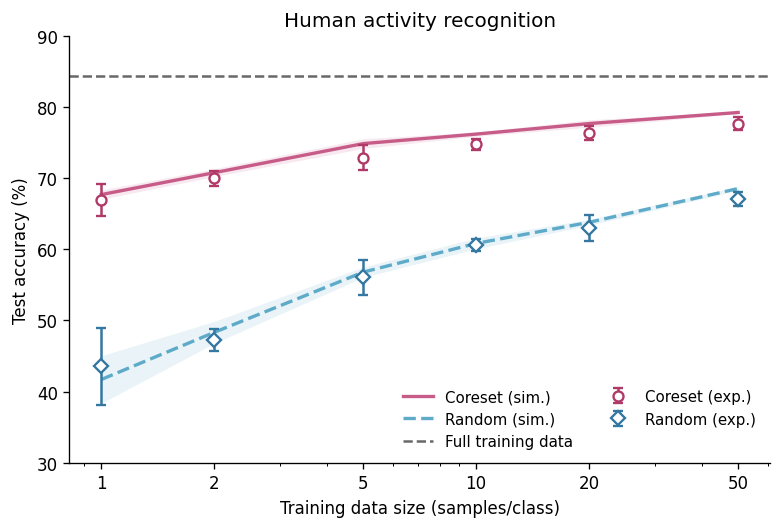

In [15]:
time_experiment = load_npz(EXPERIMENTAL / 'uci_har_experiment.npz')
display(classification_table(time_simulation, time_experiment))
print(f"Full training data: {100*float(time_simulation['full_mean']):.2f}%")
fig = plot_classification_sweep(time_simulation, time_experiment,
    'Human activity recognition', (30, 90))
plt.show()


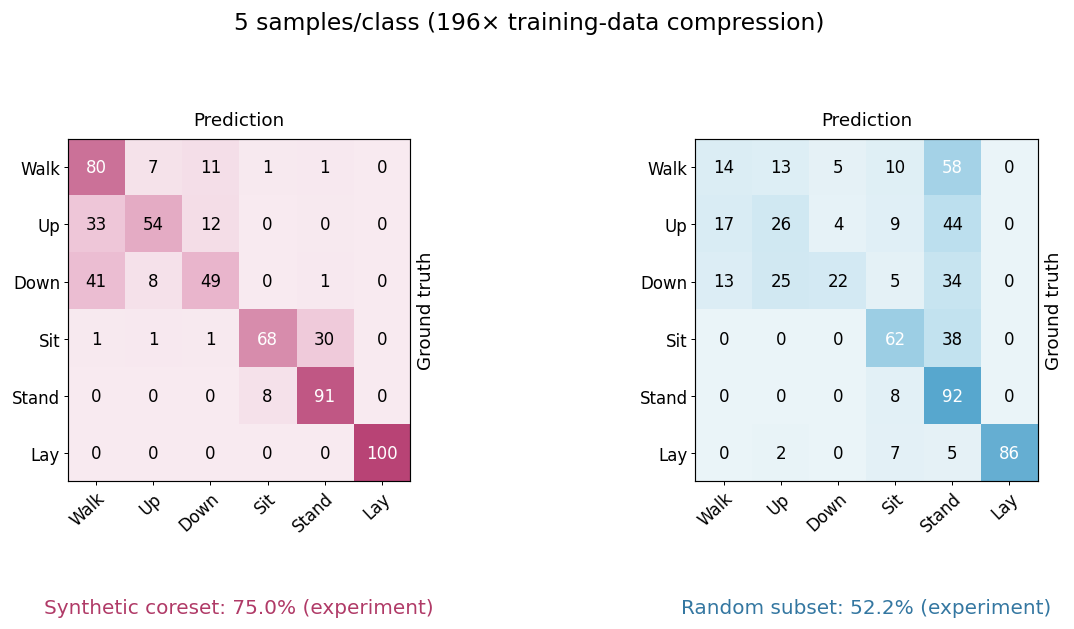

In [16]:
fig = plot_classification_confusions(time_experiment, ['Walk', 'Up', 'Down', 'Sit', 'Stand', 'Lay'],
    len(time_data['x_train']))
plt.show()
